In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn import metrics
from sklearn.model_selection import train_test_split

In [2]:
data = pd.read_csv("car_price_clean.csv")
data

,AgeYears,Mileage,EngineSize,BrandCode,Price
0,13,82396,3.8,3,41247
1,2,214221,3.0,2,37132
2,5,83870,3.8,1,41959
3,2,79944,4.2,2,53561
4,3,197011,4.6,0,37315
...,...,...,...,...,...
555,3,46346,4.3,1,45813
556,9,198192,4.8,3,44233
557,0,160119,3.8,3,53046
558,4,77640,1.7,3,49335


In [3]:
data.head()

,AgeYears,Mileage,EngineSize,BrandCode,Price
0,13,82396,3.8,3,41247
1,2,214221,3.0,2,37132
2,5,83870,3.8,1,41959
3,2,79944,4.2,2,53561
4,3,197011,4.6,0,37315


In [4]:
data.tail()

,AgeYears,Mileage,EngineSize,BrandCode,Price
555,3,46346,4.3,1,45813
556,9,198192,4.8,3,44233
557,0,160119,3.8,3,53046
558,4,77640,1.7,3,49335
559,10,167512,4.7,2,39625


In [5]:
data.iloc[555]

AgeYears          3.0
Mileage       46346.0
EngineSize        4.3
BrandCode         1.0
Price         45813.0
Name: 555, dtype: float64

In [6]:
data.shape

(560, 5)

In [7]:
list(data.columns)

['AgeYears', 'Mileage', 'EngineSize', 'BrandCode', 'Price']

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 560 entries, 0 to 559
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   AgeYears    560 non-null    int64  
 1   Mileage     560 non-null    int64  
 2   EngineSize  560 non-null    float64
 3   BrandCode   560 non-null    int64  
 4   Price       560 non-null    int64  
dtypes: float64(1), int64(4)
memory usage: 22.0 KB


In [9]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
AgeYears,560.0,6.746429,4.423064,0.0,3.0,7.0,11.0,14.0
Mileage,560.0,130965.960714,71670.299686,6062.0,69674.0,134926.5,192373.0,249833.0
EngineSize,560.0,3.008750,1.165812,1.0,2.0,3.0,4.1,5.0
BrandCode,560.0,1.483929,1.118918,0.0,0.0,2.0,2.0,3.0
Price,560.0,37090.460714,9401.758115,11670.0,30465.0,36926.5,43708.5,63570.0


In [10]:
data.isnull().sum()

AgeYears      0
Mileage       0
EngineSize    0
BrandCode     0
Price         0
dtype: int64

In [11]:
data.duplicated().sum()

np.int64(0)

In [12]:
data = data.drop_duplicates()

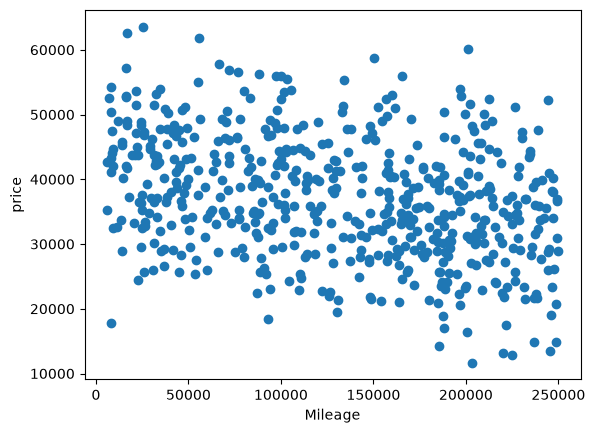

In [13]:
# تاثیر Mileage را روی Price توضیح بدید
# تاثیر AgeYears را روی Price توضیح بدید
# با رسم نمودار
plt.scatter(data["Mileage"],data["Price"])
plt.xlabel("Mileage")
plt.ylabel("price")
plt.show()

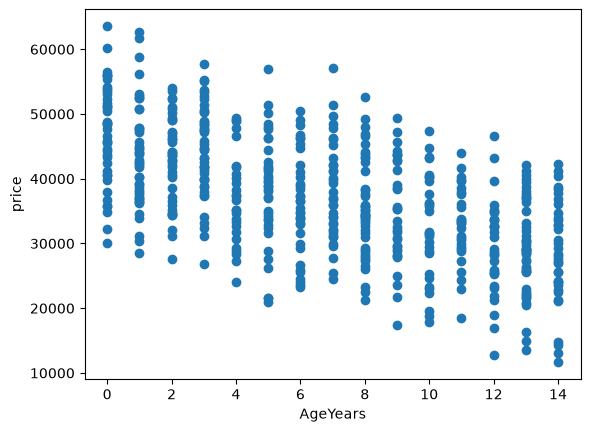

In [14]:
plt.scatter(data["AgeYears"],data["Price"])
plt.xlabel("AgeYears")
plt.ylabel("price")
plt.show()

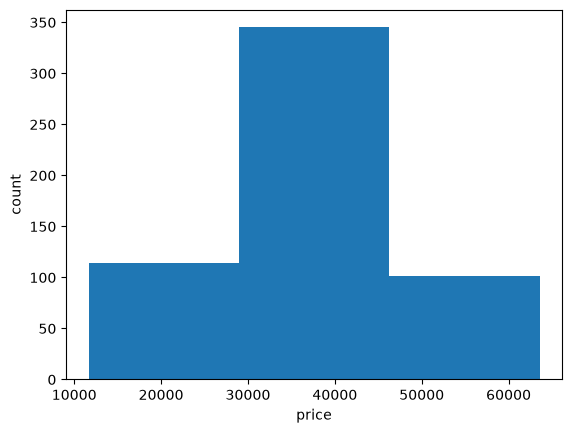

In [15]:
# یک نمودار هیستوگرام روی ستون Price بزنید
# و تعداد بازه ها را ۳ قرار بدید 
# کدام رنج بازه بیشترین تعداد ماشین را در بر میگیرد
plt.hist(data["Price"],bins=3)
plt.xlabel("price")
plt.ylabel("count")
plt.show()

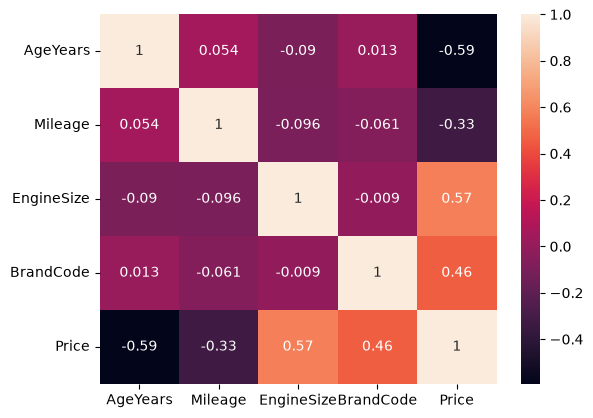

In [16]:
sns.heatmap(data.corr(),annot=True)
plt.show()

In [17]:
data.columns

Index(['AgeYears', 'Mileage', 'EngineSize', 'BrandCode', 'Price'], dtype='str')

In [18]:
data.shape

(560, 5)

In [19]:
# x = data.drop("Price", axis = 1)
x = data[['AgeYears', 'Mileage', 'EngineSize', 'BrandCode']]
y = data["Price"]

In [20]:
x_train , x_test , y_train , y_test = train_test_split(
    x,
    y,
    random_state=42,
    train_size=0.8)

In [21]:
x_train

,AgeYears,Mileage,EngineSize,BrandCode
522,0,8020,2.3,2
462,6,38266,2.0,2
0,13,82396,3.8,3
11,8,8280,1.9,3
286,12,36594,2.5,1
...,...,...,...,...
71,4,61694,3.6,1
106,1,247035,1.9,0
270,14,159263,2.8,3
435,6,37734,2.1,1


In [22]:
model = linear_model.LinearRegression()

In [23]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-1139.91, -0.03, 4039.6 , 3842.13]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['AgeYears','Mileage','EngineSize','BrandCode']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.057e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [24]:
print(x_train.iloc[0])
print(y_train[0])

AgeYears         0.0
Mileage       8020.0
EngineSize       2.3
BrandCode        2.0
Name: 522, dtype: float64
41247


In [25]:
car = [[0 , 8020 , 2.3 , 2]]
model.predict(car)

c:\Users\sama\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([47320.64845328])

In [26]:
y_test[:5]

453    44526
341    43859
177    32504
86     42561
332    33731
Name: Price, dtype: int64

In [27]:
y_pishbini = model.predict(x_test)
y_pishbini[:5]

array([41140.35864199, 41516.81526851, 28143.30364738, 39559.67879237,
       38075.06966185])

In [28]:
metrics.mean_absolute_error(y_test,y_pishbini)

2596.903741869001